### Setup
The data is set up, split, and pre-processed using the same process as before. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, GridSearchCV, cross_val_predict
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

In [2]:
X = pd.read_csv("data/model_features.csv", index_col=0)
y = pd.read_csv("data/model_target.csv", index_col=0).squeeze("columns")

y = y.astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (2500, 44)
Target shape: (2500,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (2000, 44)
Testing set: (500, 44)


### Model Evaluation
#### Baseline Model - Building the model

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print("Baseline accuracy:", baseline_accuracy)

Baseline accuracy: 0.862


#### Baseline Model - Evaluating the model

In [5]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

baseline_precision = precision_score(
    y_test, y_pred_baseline, zero_division=0
)

baseline_recall = recall_score(
    y_test, y_pred_baseline, zero_division=0
)

baseline_f1 = f1_score(
    y_test, y_pred_baseline, zero_division=0
)

print("Baseline Model Evaluation")
print("-------------------------")
print(f"Accuracy:  {baseline_accuracy:.3f}")
print(f"Precision: {baseline_precision:.3f}")
print(f"Recall:    {baseline_recall:.3f}")
print(f"F1-score:  {baseline_f1:.3f}")

Baseline Model Evaluation
-------------------------
Accuracy:  0.862
Precision: 0.000
Recall:    0.000
F1-score:  0.000


#### Baseline Evaluation Findings

The baseline model achieved 86.2% accuracy by predicting that every household would not redeem a coupon after Day 500. However, it failed to identify any households that actually redeemed coupons, resulting in zero precision, recall, and F1-score for the positive class.

This demonstrates that accuracy alone is not a sufficient measure of success for this project. A more useful model should be able to identify potential coupon redeemers, even if doing so means accepting some incorrect predictions.

#### Building a more informed Model - Logistic Regression

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)

# Build the Logistic Regression pipeline
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Train the model
lr_model.fit(X_train, y_train)

# Predict the test set
y_pred_lr = lr_model.predict(X_test)

# Get predicted probabilities for ROC-AUC
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy:  {lr_accuracy:.3f}")
print(f"Precision: {lr_precision:.3f}")
print(f"Recall:    {lr_recall:.3f}")
print(f"F1-score:  {lr_f1:.3f}")
print(f"ROC-AUC:   {lr_roc_auc:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Logistic Regression Results
---------------------------
Accuracy:  0.838
Precision: 0.227
Recall:    0.072
F1-score:  0.110
ROC-AUC:   0.794

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.96      0.91       431
           1       0.23      0.07      0.11        69

    accuracy                           0.84       500
   macro avg       0.55      0.52      0.51       500
weighted avg       0.78      0.84      0.80       500



#### Logistic Regression Evaluation

The Logistic Regression model achieved **83.8% accuracy** and a ROC-AUC score of **0.794**, indicating that it has some ability to distinguish between future coupon redeemers and non-redeemers.

However, the model identified only **7.2% of actual coupon redeemers**, with a recall of 0.072. Out of 69 households that redeemed coupons in the test set, it correctly identified only 5. Its precision was also low at 22.7%, meaning that many of the households predicted to redeem coupons did not actually redeem them.

Although the model performs reasonably well overall, it misses most future coupon redeemers. This suggests that the model is biased toward predicting the majority class. The next step is to address this imbalance by evaluating a **balanced Logistic Regression model**.

#### Balanced Logistic Regression Model

In [7]:
# Build a balanced Logistic Regression model
balanced_lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train the model
balanced_lr_model.fit(X_train, y_train)

# Generate predictions
y_pred_balanced = balanced_lr_model.predict(X_test)
y_prob_balanced = balanced_lr_model.predict_proba(X_test)[:, 1]

# Evaluate the model
balanced_accuracy = accuracy_score(y_test, y_pred_balanced)
balanced_precision = precision_score(
    y_test, y_pred_balanced, zero_division=0
)
balanced_recall = recall_score(
    y_test, y_pred_balanced, zero_division=0
)
balanced_f1 = f1_score(
    y_test, y_pred_balanced, zero_division=0
)
balanced_roc_auc = roc_auc_score(y_test, y_prob_balanced)

print("Balanced Logistic Regression Results")
print("------------------------------------")
print(f"Accuracy:  {balanced_accuracy:.3f}")
print(f"Precision: {balanced_precision:.3f}")
print(f"Recall:    {balanced_recall:.3f}")
print(f"F1-score:  {balanced_f1:.3f}")
print(f"ROC-AUC:   {balanced_roc_auc:.3f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_balanced, zero_division=0
))

Balanced Logistic Regression Results
------------------------------------
Accuracy:  0.782
Precision: 0.336
Recall:    0.594
F1-score:  0.429
ROC-AUC:   0.811

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.81      0.87       431
           1       0.34      0.59      0.43        69

    accuracy                           0.78       500
   macro avg       0.63      0.70      0.65       500
weighted avg       0.84      0.78      0.81       500



### Balanced Logistic Regression Evaluation

The balanced Logistic Regression model was introduced to improve the identification of future coupon redeemers, who represent a minority of the dataset.

Compared with the standard Logistic Regression model, recall increased from **7.2% to 59.4%**, meaning the balanced model identified 41 out of the 69 actual coupon redeemers in the test set. Its F1-score also improved from 0.110 to 0.429, while ROC-AUC increased from 0.794 to 0.811.

However, accuracy decreased from 83.8% to 78.2%, and precision remained relatively low at 33.6%. This means the model identifies more potential coupon redeemers but also produces more false positives.

Overall, balancing the classes improves the model's ability to identify coupon redeemers. This is useful for a business that wants to reach more potential redeemers, although the cost of contacting households that do not redeem coupons should also be considered.

### Comparing Model Performance

In [8]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        lr_accuracy,
        balanced_accuracy
    ],
    "Precision": [
        baseline_precision,
        lr_precision,
        balanced_precision
    ],
    "Recall": [
        baseline_recall,
        lr_recall,
        balanced_recall
    ],
    "F1-score": [
        baseline_f1,
        lr_f1,
        balanced_f1
    ],
    "ROC-AUC": [
        np.nan,
        lr_roc_auc,
        balanced_roc_auc
    ]
})

model_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline,0.862,0.000,0.000,0.000,NaN
1,Logistic Regression,0.838,0.227,0.072,0.110,0.794
2,Balanced Logistic Regression,0.782,0.336,0.594,0.429,0.811


#### Model Comparison Findings

The baseline model achieved the highest accuracy at 86.2%, but it failed to identify any future coupon redeemers. This demonstrates why accuracy alone is not sufficient for evaluating model performance.

Standard Logistic Regression achieved 83.8% accuracy but identified only 7.2% of actual coupon redeemers. Although it performed reasonably well overall, it was not effective at identifying the households most relevant to the project's objective.

Balanced Logistic Regression achieved a lower accuracy of 78.2%, but substantially improved recall to 59.4% and F1-score to 0.429. It also achieved the highest ROC-AUC of 0.811 among the two Logistic Regression models.

Overall, Balanced Logistic Regression is the most promising of the three models for identifying potential coupon redeemers. Its lower accuracy reflects a trade-off: it identifies more actual redeemers while also incorrectly flagging some non-redeemers. The suitability of this trade-off depends on the business cost of missed opportunities versus unnecessary coupon targeting.

### Checking Model Consistency - Cross Validation

To assess whether the model's performance is consistent, we use five-fold stratified cross-validation on the training data. The training set is divided into five parts, with the model trained and evaluated across different combinations of these parts.

This provides a more reliable picture of model performance than relying on a single train-test split alone.

In [9]:

# Set up five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Choose the evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Evaluate the balanced Logistic Regression model
cv_results = cross_validate(
    balanced_lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

# Display the average score and standard deviation
for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} ± {scores.std():.3f}"
    )


Accuracy: 0.788 ± 0.020
Precision: 0.357 ± 0.036
Recall: 0.667 ± 0.061
F1: 0.465 ± 0.043
Roc_auc: 0.810 ± 0.012


#### Evaluating Cross-Validation Results

Five-fold stratified cross-validation was performed on the training data to evaluate the consistency of the Balanced Logistic Regression model.

The model achieved an average accuracy of 78.8%, precision of 35.7%, recall of 66.7%, F1-score of 0.465, and ROC-AUC of 0.810 across the five folds.

The average recall of 66.7% indicates that the model identified approximately two-thirds of actual coupon redeemers across the cross-validation evaluations. The ROC-AUC score of 0.810 also suggests that the model can reasonably distinguish between households that redeem coupons and those that do not.

The standard deviations were relatively small across all metrics, particularly for accuracy (±0.020) and ROC-AUC (±0.012). This suggests that the model's performance was reasonably consistent across different subsets of the training data.

Overall, cross-validation supports the potential of Balanced Logistic Regression for identifying future coupon redeemers. However, its precision of 35.7% indicates that many households flagged as potential redeemers may not actually redeem coupons. This trade-off should be considered when deciding how the model could be used in a real marketing campaign.

### Threshold Tuning

Logistic Regression uses a default classification threshold of 0.5 to classify households as potential coupon redeemers. However, this threshold may not be optimal for a dataset in which redeemers represent a minority of households.

Threshold tuning allows us to explore how different probability thresholds affect precision, recall, and F1-score. A lower threshold may identify more actual coupon redeemers, but it may also increase the number of households incorrectly predicted to redeem coupons.

In this project, we use cross-validated predictions from the training data to compare different thresholds and identify a suitable balance between identifying potential redeemers and limiting false positives.

In [10]:
# Generate cross-validated probabilities for the positive class
y_prob_cv = cross_val_predict(
    balanced_lr_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Evaluate different classification thresholds
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_cv >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_train, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, y_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)


,Threshold,Precision,Recall,F1-score
0,0.3,0.262,0.877,0.404
1,0.4,0.305,0.764,0.436
2,0.5,0.357,0.667,0.465
3,0.6,0.400,0.558,0.466
4,0.7,0.428,0.449,0.438


#### Threshold Tuning Results

The results show that the classification threshold affects the balance between precision and recall.

At a threshold of 0.3, the model achieved a recall of 87.7%, identifying a larger proportion of actual coupon redeemers. However, precision was only 26.2%, indicating that many households predicted to redeem coupons did not actually redeem them.

As the threshold increased, precision generally improved while recall decreased. At a threshold of 0.7, precision reached 42.8%, but recall dropped to 44.9%, meaning the model missed more actual coupon redeemers.

The highest F1-score was achieved at a threshold of 0.6, with a score of 0.466. This was only marginally higher than the F1-score of 0.465 at the default threshold of 0.5. Therefore, changing the threshold to 0.6 provides little improvement in the overall balance between precision and recall.

Overall, the choice of threshold depends on the business objective. A lower threshold may be appropriate when the priority is to identify as many potential coupon redeemers as possible, while a higher threshold may be preferred when marketing resources are limited. Based on F1-score alone, a threshold of 0.6 is the best among the five thresholds tested, although its improvement over 0.5 is negligible.

### Feature Importance and Interpretation

Understanding model performance is important, but it is also useful to identify which features contribute to the model's predictions. Feature importance provides insight into the household purchasing behaviors associated with future coupon redemption.

For this project, we examine the coefficients of the Balanced Logistic Regression model. Positive coefficients indicate that higher feature values are associated with higher predicted odds of coupon redemption, while negative coefficients indicate an association with lower predicted odds, holding other features constant.

Because the model uses standardized features, the coefficient magnitudes can be compared more meaningfully across features. However, these coefficients represent associations rather than proof of causation. They help explain the model's predictions but do not establish that a particular purchasing behavior causes coupon redemption.

In [11]:
# Extract feature names and coefficients from the fitted model
feature_names = X_train.columns
coefficients = balanced_lr_model.named_steps["model"].coef_[0]

# Create a DataFrame of feature coefficients
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute Coefficient",
    ascending=False
)

# Display the 15 features with the largest coefficients
feature_importance.head(15)


,Feature,Coefficient,Absolute Coefficient
20,GROCERY,0.794076,0.794076
3,Avg_Quantity_Per_Basket,0.773857,0.773857
2,Avg_Basket_Value,-0.663343,0.663343
8,CNTRL/STORE SUP,-0.486314,0.486314
21,HBC,-0.449932,0.449932
0,Total_Spending,0.446930,0.446930
24,MEAT-PCKGD,-0.357422,0.357422
34,PRODUCE,0.320003,0.320003
15,FLORAL,-0.232280,0.232280
25,MISC SALES TRAN,0.231014,0.231014


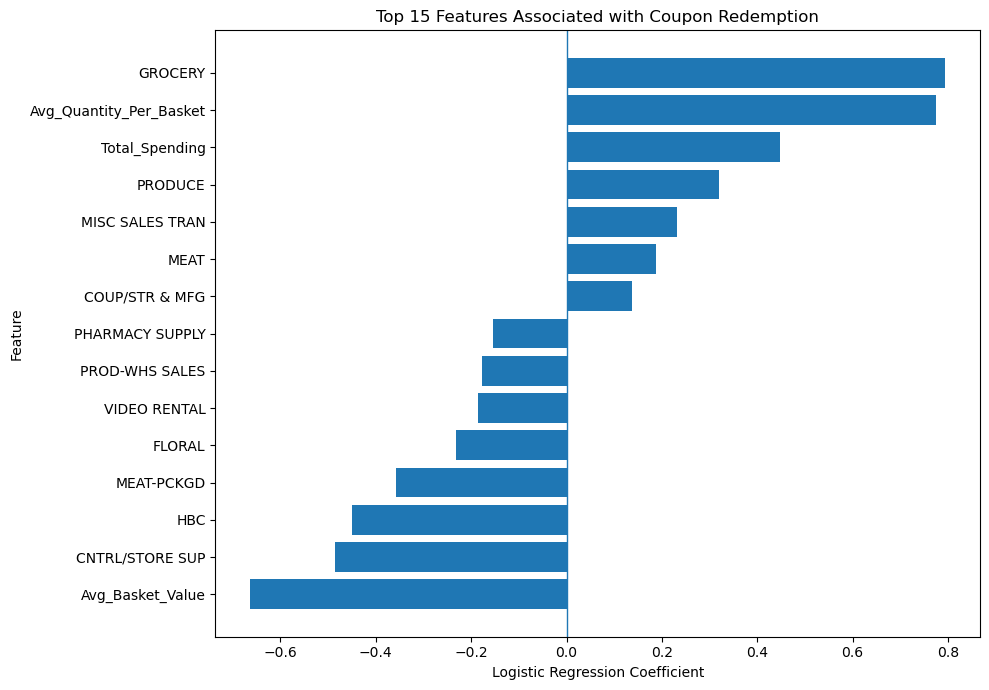

In [12]:
# Select the 15 features with the largest absolute coefficients
top_features = feature_importance.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Features Associated with Coupon Redemption")
plt.tight_layout()
plt.show()


#### Feature Importance Findings

The coefficient analysis identifies several household purchasing features associated with future coupon redemption.

GROCERY had the largest positive coefficient, followed by Avg_Quantity_Per_Basket and Total_Spending. This suggests that grocery-related purchasing activity, the quantity of items purchased per basket, and overall spending are important signals used by the model when estimating future coupon redemption.

In contrast, Avg_Basket_Value had the largest negative coefficient among the features examined. CNTRL/STORE SUP and HBC also showed relatively strong negative coefficients. These relationships indicate that higher values in these features are associated with lower predicted odds of coupon redemption, holding other features constant.

An interesting finding is that Total_Spending and Avg_Quantity_Per_Basket have positive coefficients, whereas Avg_Basket_Value has a negative coefficient. This suggests that overall spending, purchase quantity, and average basket value may capture different aspects of household purchasing behavior.

These findings can help inform future marketing strategies by identifying purchasing patterns that may be useful for customer segmentation and coupon targeting. However, the coefficients indicate associations rather than causal relationships, and correlated features may influence their individual magnitudes. Further analysis would be needed before treating these patterns as established customer behavior.

### Final Evaluation on the Test Set

In [13]:
# Get predicted probabilities from the fitted balanced model
y_prob_test = balanced_lr_model.predict_proba(X_test)[:, 1]

# Compare the default and tuned thresholds
final_thresholds = [0.5, 0.6]
final_results = []

for threshold in final_thresholds:
    y_pred = (y_prob_test >= threshold).astype(int)

    final_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob_test)
    })

final_results_df = pd.DataFrame(final_results)
final_results_df.round(3)


,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.5,0.782,0.336,0.594,0.429,0.811
1,0.6,0.810,0.365,0.507,0.424,0.811


### Final Test-Set Evaluation Results

The Balanced Logistic Regression model was evaluated on the held-out test set using classification thresholds of 0.5 and 0.6.

At the default threshold of 0.5, the model achieved 78.2% accuracy, 33.6% precision, 59.4% recall, an F1-score of 0.429, and a ROC-AUC score of 0.811.

At the tuned threshold of 0.6, accuracy increased to 81.0% and precision improved to 36.5%. However, recall decreased to 50.7%, and the F1-score declined slightly to 0.424. The ROC-AUC remained unchanged at 0.811 because both evaluations used the same predicted probabilities.

These results demonstrate the trade-off associated with adjusting the classification threshold. The threshold of 0.6 produces fewer positive predictions and improves accuracy and precision, but it identifies fewer actual coupon redeemers. The threshold of 0.5 achieves higher recall and a slightly better F1-score, making it more suitable when identifying potential redeemers is a priority.

Overall, the threshold of 0.5 is preferred if the business objective is to identify more households likely to redeem coupons. The threshold of 0.6 may be more appropriate if marketing resources are limited and reducing unnecessary targeting is more important. The final choice should depend on the business cost of missed redemption opportunities versus contacting households that do not redeem coupons.

## Conclusion and Business Recommendations

### Conclusion

This project aimed to predict future coupon redemption using household purchasing behavior observed before Day 500. The analysis compared a baseline model with standard and balanced Logistic Regression, followed by cross-validation, threshold tuning, and feature-importance analysis.

The baseline model achieved 86.2% accuracy by predicting that every household would not redeem a coupon. However, it failed to identify any actual coupon redeemers, demonstrating that accuracy alone is insufficient for evaluating performance on an imbalanced dataset.

Standard Logistic Regression achieved a ROC-AUC score of 0.794 but identified only 7.2% of actual coupon redeemers at the default threshold. Balanced Logistic Regression improved recall to 59.4% and the F1-score to 0.429 on the held-out test set, with a ROC-AUC score of 0.811. These results indicate that accounting for class imbalance substantially improved the model's ability to identify potential redeemers.

Five-fold stratified cross-validation produced a mean ROC-AUC of 0.810 and a mean F1-score of 0.465, suggesting that the model's predictive performance was reasonably consistent across different training-data splits.

Threshold tuning revealed a trade-off between identifying more potential redeemers and reducing false positives. The default threshold of 0.5 achieved higher recall and a slightly higher F1-score on the test set than the threshold of 0.6. Therefore, the default threshold is preferable when identifying more potential coupon redeemers is the primary objective.

Feature-importance analysis also identified purchasing variables associated with the model's predictions. GROCERY, Avg_Quantity_Per_Basket, and Total_Spending had the strongest positive coefficients among the displayed features, while Avg_Basket_Value had the strongest negative coefficient. These findings provide potential directions for further customer-behavior analysis.

Overall, Balanced Logistic Regression is the most promising model among those evaluated for this project's objective. However, its precision of 33.6% at the default threshold indicates that many households predicted to redeem coupons did not actually redeem them. The model should therefore be treated as a decision-support tool rather than a definitive predictor of customer behavior.

### Business Recommendations

**1. Use the model to prioritize coupon targeting.**

The retailer could use predicted redemption probabilities to identify households for targeted coupon campaigns. The model should support marketing decisions rather than automatically determine which households receive offers.

**2. Align the prediction threshold with marketing objectives.**

A threshold of 0.5 is appropriate when the priority is to identify more potential redeemers. A higher threshold could be considered when marketing budgets are limited and the retailer wants to reduce the number of households contacted. The final threshold should be informed by campaign costs and redemption value.

**3. Use purchasing behavior to inform customer segmentation.**

The model's coefficients suggest that grocery activity, purchase quantity, and total spending may be useful variables for further investigation. The retailer could examine whether different purchasing patterns correspond to different responses to coupon campaigns.

**4. Evaluate campaign profitability before implementation.**

Predicting redemption does not necessarily mean maximizing profit. Before deploying the model, the retailer should estimate campaign costs, coupon discounts, incremental purchases, and profit margins. A controlled marketing experiment could determine whether targeted coupons generate more incremental profit than a general coupon campaign.

**5. Improve and monitor the model over time.**

Future work could explore additional algorithms, refine customer features, assess performance across customer segments, and monitor changes in redemption behavior. Any future model should be compared using appropriate classification metrics and evaluated on data not used for model selection.

### Limitations and Future Work

This analysis has several limitations. First, coupon redeemers represent a minority of the dataset, making precision and recall especially important. Second, feature coefficients describe associations rather than causal relationships. Third, predicting coupon redemption does not establish whether a coupon caused a customer to make an additional purchase.

Future work could include testing additional models, examining permutation importance, evaluating probability calibration, and conducting controlled coupon campaigns to measure incremental redemption and profitability.

### Final Summary

Balanced Logistic Regression improved the identification of future coupon redeemers compared with the baseline and standard Logistic Regression models. Its test-set ROC-AUC of 0.811 and recall of 59.4% demonstrate useful predictive potential, although its precision and false-positive rate remain important considerations. With further validation and business-impact testing, the model could help a retailer prioritize coupon campaigns and make more informed customer-targeting decisions.